# Hands-On Data Lab Implementation
**AI ML Research Specialist Internship — Task 2** · Submitted by: Pranav

This notebook sets up a data-analysis environment and works through practical exercises on **Pandas & NumPy**, **data cleaning**, **visualization**, and **basic analysis**.

**Dataset note:** the internship brief gives no dataset, so I generated a *synthetic, deliberately messy* retail dataset (orders, customers, products) with a fixed random seed. It is not real business data; the goal is to practise the techniques on realistic problems (missing values, duplicates, inconsistent labels, wrong types, outliers). Re-running the notebook reproduces every number.

**Contents:** 1 Environment · 2 Load data · 3 Pandas & NumPy · 4 Cleaning · 5 Visualization · 6 Analysis · 7 Scikit-learn check · 8 Insights

## 1. Environment Setup

Installation (run once in a terminal; a virtual environment keeps the project reproducible):
```bash
python -m venv ds-env
source ds-env/bin/activate        # Windows: ds-env\Scripts\activate
pip install jupyter numpy pandas matplotlib seaborn scikit-learn
jupyter notebook                  # opens Jupyter in the browser
```

In [1]:
import sys, platform
import numpy as np, pandas as pd, matplotlib, seaborn as sns, sklearn
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0], "on", platform.system())
for lib in (np, pd, matplotlib, sns, sklearn):
    print(f"{lib.__name__:12}:", lib.__version__)

SEED = 42
rng = np.random.default_rng(SEED)           # reproducible randomness
pd.set_option("display.max_columns", 20, "display.width", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})

Python      : 3.13.16 on Linux
numpy       : 2.5.3
pandas      : 3.0.5
matplotlib  : 3.11.2
seaborn     : 0.13.2
sklearn     : 1.9.1


## 2. Creating and Loading the Datasets

In [2]:
n = 400
products = pd.DataFrame({
    "product_id": [f"P{i:02d}" for i in range(1, 11)],
    "product_name": ["Notebook","Pen Set","Backpack","Desk Lamp","Headphones","Water Bottle","Calculator","Mouse","Keyboard","Planner"],
    "category": ["Stationery","Stationery","Accessories","Home","Electronics","Accessories","Electronics","Electronics","Electronics","Stationery"],
    "unit_price": [120, 250, 1200, 800, 1800, 450, 650, 700, 1500, 300],
})
customers = pd.DataFrame({
    "customer_id": [f"C{i:03d}" for i in range(1, 61)],
    "region": rng.choice(["North","South","East","West"], 60),
    "segment": rng.choice(["Student","Professional","Business"], 60, p=[.5,.3,.2]),
})
orders = pd.DataFrame({
    "order_id": np.arange(1001, 1001 + n),
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.choice(customers["customer_id"], n),
    "product_id": rng.choice(products["product_id"], n),
    "quantity": rng.integers(1, 6, n),
    "discount_pct": rng.choice([0, 5, 10, 15, 20], n, p=[.4,.2,.2,.1,.1]),
    "rating": rng.choice([1,2,3,4,5], n, p=[.05,.1,.2,.35,.3]).astype(float),
    "payment_mode": rng.choice(["UPI","Card","Cash","NetBanking"], n, p=[.45,.3,.15,.1]),
})

# ---- inject realistic data-quality problems ----
orders.loc[rng.choice(n, 30, replace=False), "rating"] = np.nan                  # missing ratings
orders.loc[rng.choice(n, 12, replace=False), "customer_id"] = np.nan             # missing customer
orders = pd.concat([orders, orders.sample(15, random_state=SEED)], ignore_index=True)   # duplicate rows
orders["payment_mode"] = orders["payment_mode"].mask(rng.random(len(orders)) < .08, "upi ")  # inconsistent label
orders["payment_mode"] = orders["payment_mode"].mask(rng.random(len(orders)) < .05, "CARD")
orders["order_date"] = orders["order_date"].dt.strftime("%Y-%m-%d")              # dates stored as text
orders["quantity"] = orders["quantity"].astype(str)                              # numbers stored as text
orders.loc[[10, 200], "quantity"] = ["500", "-3"]                                # impossible values
orders.to_csv("orders_raw.csv", index=False)
customers.to_csv("customers.csv", index=False); products.to_csv("products.csv", index=False)

orders = pd.read_csv("orders_raw.csv")       # load back from disk like a real project
customers = pd.read_csv("customers.csv"); products = pd.read_csv("products.csv")
print("orders   :", orders.shape, "| customers:", customers.shape, "| products:", products.shape)
orders.head()

orders   : (415, 8) | customers: (60, 3) | products: (10, 4)


,order_id,order_date,customer_id,product_id,quantity,discount_pct,rating,payment_mode
0,1001,2025-12-09,C006,P06,5,0,4.0,Cash
1,1002,2025-02-25,C051,P08,2,20,4.0,NetBanking
2,1003,2025-07-01,C007,P06,2,0,4.0,UPI
3,1004,2025-09-12,C004,P07,5,0,3.0,Card
4,1005,2025-06-30,C025,P06,2,10,3.0,Card


In [3]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   order_id      415 non-null    int64  
 1   order_date    415 non-null    str    
 2   customer_id   402 non-null    str    
 3   product_id    415 non-null    str    
 4   quantity      415 non-null    int64  
 5   discount_pct  415 non-null    int64  
 6   rating        384 non-null    float64
 7   payment_mode  415 non-null    str    
dtypes: float64(1), int64(3), str(4)
memory usage: 26.1 KB


In [4]:
orders.describe(include='all').T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,415.0,NaN,NaN,NaN,1198.961446,115.604956,1001.0,1097.5,1199.0,1298.5,1400.0
order_date,415,250,2025-02-25,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,402,60,C006,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,415,10,P06,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,415.0,NaN,NaN,NaN,4.13494,24.442797,-3.0,2.0,3.0,4.0,500.0
discount_pct,415.0,NaN,NaN,NaN,6.445783,6.851166,0.0,0.0,5.0,10.0,20.0
rating,384.0,NaN,NaN,NaN,3.789062,1.102944,1.0,3.0,4.0,5.0,5.0
payment_mode,415,6,UPI,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Working with Data using Pandas & NumPy

Tidy copies are used for the exercises in this section; formal cleaning follows in Section 4.

### 3.1 Selection, filtering and sorting

In [5]:
o = orders.copy()
o["quantity"] = pd.to_numeric(o["quantity"])
print("Select columns:"); display(o[["order_id", "product_id", "quantity"]].head(3))
print("loc  (rows 0-2, two columns):"); display(o.loc[0:2, ["order_id", "rating"]])
print("iloc (first row, first 4 cols):"); display(o.iloc[[0], :4])

bulk = o[(o["quantity"] >= 4) & (o["discount_pct"] >= 15)]           # boolean filtering
print("Orders with quantity>=4 and discount>=15%:", len(bulk))
print("UPI-like payments:", o["payment_mode"].str.strip().str.lower().eq("upi").sum())
print(o.query("rating == 5 and quantity > 3").shape[0], "five-star orders with quantity > 3")
o.sort_values(["discount_pct", "quantity"], ascending=[False, False]).head(5)

Select columns:


,order_id,product_id,quantity
0,1001,P06,5
1,1002,P08,2
2,1003,P06,2


loc  (rows 0-2, two columns):


,order_id,rating
0,1001,4.0
1,1002,4.0
2,1003,4.0


iloc (first row, first 4 cols):


,order_id,order_date,customer_id,product_id
0,1001,2025-12-09,C006,P06


Orders with quantity>=4 and discount>=15%: 30
UPI-like payments: 192
42 five-star orders with quantity > 3


,order_id,order_date,customer_id,product_id,quantity,discount_pct,rating,payment_mode
76,1077,2025-09-05,NaN,P05,5,20,3.0,NetBanking
90,1091,2025-04-18,C058,P07,5,20,NaN,UPI
183,1184,2025-11-23,C057,P06,5,20,4.0,NetBanking
218,1219,2025-04-13,C019,P09,5,20,3.0,upi
239,1240,2025-07-04,C060,P05,5,20,3.0,UPI


### 3.2 Merging (joining) tables

In [6]:
merged = (o.merge(products, on="product_id", how="left")
            .merge(customers, on="customer_id", how="left"))
merged["revenue"] = merged["quantity"] * merged["unit_price"] * (1 - merged["discount_pct"] / 100)
print(merged.shape)
merged[["order_id","product_name","category","region","segment","quantity","unit_price","discount_pct","revenue"]].head()

(415, 14)


,order_id,product_name,category,region,segment,quantity,unit_price,discount_pct,revenue
0,1001,Water Bottle,Accessories,West,Student,5,450,0,2250.0
1,1002,Mouse,Electronics,West,Professional,2,700,20,1120.0
2,1003,Water Bottle,Accessories,North,Student,2,450,0,900.0
3,1004,Calculator,Electronics,South,Student,5,650,0,3250.0
4,1005,Water Bottle,Accessories,West,Professional,2,450,10,810.0


### 3.3 Grouping and aggregation

In [7]:
good = merged[merged["quantity"].between(1, 10)].drop_duplicates()     # quick filter for this demo only
by_cat = good.groupby("category").agg(orders=("order_id","count"), units=("quantity","sum"),
                                      revenue=("revenue","sum"), avg_rating=("rating","mean")).round(1)
display(by_cat.sort_values("revenue", ascending=False))

pivot = good.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum", fill_value=0).round(0)
display(pivot)

,orders,units,revenue,avg_rating
category,,,,
Electronics,170,505,562687.5,3.8
Accessories,78,228,161512.5,3.5
Home,42,122,93480.0,4.1
Stationery,112,330,69213.5,3.9


category,Accessories,Electronics,Home,Stationery
region,,,,
East,33232.0,151620.0,25560.0,15206.0
North,28365.0,143710.0,14520.0,19238.0
South,23108.0,73022.0,15680.0,16904.0
West,74648.0,178035.0,37720.0,16315.0


### 3.4 Transformation (new columns, binning, dates)

In [8]:
good = good.copy()
good["order_date"] = pd.to_datetime(good["order_date"])
good["month"] = good["order_date"].dt.to_period("M").astype(str)
good["weekday"] = good["order_date"].dt.day_name()
good["order_size"] = pd.cut(good["revenue"], [0, 500, 2000, np.inf], labels=["Small", "Medium", "Large"])
good["revenue_rank"] = good["revenue"].rank(ascending=False, method="dense")
print(good["order_size"].value_counts())
good[["order_date","month","weekday","revenue","order_size"]].head(4)

order_size
Medium    175
Large     164
Small      63
Name: count, dtype: int64


,order_date,month,weekday,revenue,order_size
0,2025-12-09,2025-12,Tuesday,2250.0,Large
1,2025-02-25,2025-02,Tuesday,1120.0,Medium
2,2025-07-01,2025-07,Tuesday,900.0,Medium
3,2025-09-12,2025-09,Friday,3250.0,Large


### 3.5 NumPy numerical operations

In [9]:
rev = good["revenue"].to_numpy()
print("Array shape/dtype:", rev.shape, rev.dtype)
print("mean / median / std :", rev.mean().round(1), np.median(rev).round(1), rev.std(ddof=1).round(1))
print("percentiles 25/50/75/95:", np.percentile(rev, [25, 50, 75, 95]).round(1))
print("z-score normalised, first 5:", ((rev - rev.mean()) / rev.std(ddof=1))[:5].round(2))
print("log1p skew reduction:", round(pd.Series(rev).skew(), 2), "->", round(pd.Series(np.log1p(rev)).skew(), 2))

m = np.arange(12).reshape(3, 4)            # broadcasting / axis demo
print("\nmatrix:\n", m, "\ncolumn sums:", m.sum(axis=0), "| row means:", m.mean(axis=1))
print("matrix * [1,10,100,1000]:\n", m * np.array([1, 10, 100, 1000]))
print("np.where example:", np.where(rev > 2000, "high", "normal")[:6])

Array shape/dtype: (402,) float64
mean / median / std : 2206.2 1500.0 1973.2
percentiles 25/50/75/95: [ 700.  1500.  3134.4 6718.5]
z-score normalised, first 5: [ 0.02 -0.55 -0.66  0.53 -0.71]
log1p skew reduction: 1.31 -> -0.3

matrix:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 
column sums: [12 15 18 21] | row means: [1.5 5.5 9.5]
matrix * [1,10,100,1000]:
 [[    0    10   200  3000]
 [    4    50   600  7000]
 [    8    90  1000 11000]]
np.where example: ['high' 'normal' 'normal' 'high' 'normal' 'normal']


**Observations:** Electronics is only 170 of 402 orders in this slice but brings in the most revenue (about ₹563k), while Stationery has 112 orders and the least revenue (about ₹69k) because its unit prices are low. West is the strongest region for Accessories and Electronics. Revenue is right-skewed: the mean (₹2,206) is well above the median (₹1,500), and a log transform reduces the skewness from 1.31 to -0.30, which is why log scales are used for plots later.

## 4. Data Cleaning

### 4.1 Step 1: audit — find the problems first

In [10]:
print("Rows:", len(orders))
print("\nMissing values:"); print(orders.isna().sum()[lambda s: s > 0])
print("\nDuplicate rows (all columns):", orders.duplicated().sum())
print("Duplicate order_id:", orders["order_id"].duplicated().sum())
print("\nDtypes:"); print(orders.dtypes)
print("\npayment_mode values:", sorted(orders["payment_mode"].unique()))
print("quantity as number -> min/max:", pd.to_numeric(orders["quantity"]).min(), pd.to_numeric(orders["quantity"]).max())

Rows: 415

Missing values:
customer_id    13
rating         31
dtype: int64

Duplicate rows (all columns): 11
Duplicate order_id: 15

Dtypes:
order_id          int64
order_date          str
customer_id         str
product_id          str
quantity          int64
discount_pct      int64
rating          float64
payment_mode        str
dtype: object

payment_mode values: ['CARD', 'Card', 'Cash', 'NetBanking', 'UPI', 'upi ']
quantity as number -> min/max: -3 500


### 4.2 Step 2: fix them (on a copy; raw data stays untouched)

In [11]:
clean = orders.copy()

# 1) duplicates
before = len(clean); clean = clean.drop_duplicates(subset="order_id", keep="first")
print(f"Duplicates removed: {before - len(clean)}")

# 2) wrong data types
clean["order_date"] = pd.to_datetime(clean["order_date"])
clean["quantity"] = pd.to_numeric(clean["quantity"])

# 3) inconsistent categories
clean["payment_mode"] = clean["payment_mode"].str.strip().str.lower().replace({"upi": "UPI", "card": "Card", "cash": "Cash", "netbanking": "NetBanking"})
print("payment_mode now:", sorted(clean["payment_mode"].unique()))

# 4) impossible values (quantity must be 1-10)
bad = ~clean["quantity"].between(1, 10)
print("Impossible quantities dropped:", clean.loc[bad, "quantity"].tolist())
clean = clean[~bad]

# 5) missing values: a missing customer cannot be guessed -> drop; missing rating -> keep as NaN + flag
print("Rows without customer_id dropped:", clean["customer_id"].isna().sum())
clean = clean.dropna(subset=["customer_id"])
clean["rating_missing"] = clean["rating"].isna()
clean["rating_filled"] = clean["rating"].fillna(clean["rating"].median())      # median is robust for ordinal ratings

# 6) memory-friendly types
for col in ["payment_mode"]: clean[col] = clean[col].astype("category")
clean = clean.reset_index(drop=True)
print("\nCleaned shape:", clean.shape, "(raw:", orders.shape, ")")

Duplicates removed: 15
payment_mode now: ['Card', 'Cash', 'NetBanking', 'UPI']
Impossible quantities dropped: [500, -3]
Rows without customer_id dropped: 12

Cleaned shape: (386, 10) (raw: (415, 8) )


### 4.3 Step 3: validate the result

In [12]:
checks = {
    "no duplicate order_id": clean["order_id"].is_unique,
    "no missing customer_id": clean["customer_id"].notna().all(),
    "quantity in 1..10": clean["quantity"].between(1, 10).all(),
    "dates parsed": pd.api.types.is_datetime64_any_dtype(clean["order_date"]),
    "payment modes standard": set(clean["payment_mode"].astype(str)) == {"UPI","Card","Cash","NetBanking"},
    "ratings in 1..5": clean["rating_filled"].between(1, 5).all(),
}
for k, v in checks.items(): print(("PASS" if v else "FAIL"), "-", k)
assert all(checks.values())
df = (clean.merge(products, on="product_id", how="left").merge(customers, on="customer_id", how="left"))
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)
df["month"] = df["order_date"].dt.month
df.to_csv("orders_clean.csv", index=False)
print("\nAnalysis table:", df.shape, "| total revenue: ₹{:,.0f}".format(df['revenue'].sum()))

PASS - no duplicate order_id
PASS - no missing customer_id
PASS - quantity in 1..10
PASS - dates parsed
PASS - payment modes standard
PASS - ratings in 1..5

Analysis table: (386, 17) | total revenue: ₹846,644


**Observations:** The audit found 13 missing customer IDs and 31 missing ratings, 15 duplicated order IDs, mixed-case and padded payment labels (`CARD`, `upi `), dates and quantities stored as text, and two impossible quantities (500 and -3). After cleaning, 29 of the 415 raw rows were removed (7%) and 386 remain. Missing ratings were kept with a flag column and filled with the median only in a separate column, so the original information is not lost.

## 5. Data Visualization

### 5.1 Bar chart: revenue by category

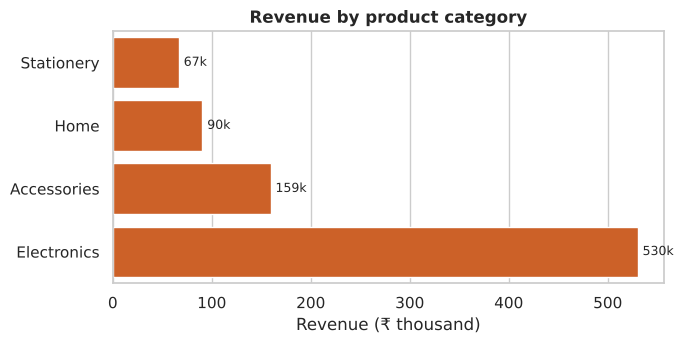

In [13]:
cat_rev = df.groupby("category")["revenue"].sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.barplot(x=cat_rev.values / 1000, y=cat_rev.index, color="#E8590C", ax=ax)
for i, v in enumerate(cat_rev.values / 1000): ax.text(v + 5, i, f"{v:,.0f}k", va="center", fontsize=9)
ax.set(title="Revenue by product category", xlabel="Revenue (₹ thousand)", ylabel="")
plt.tight_layout(); plt.show()

### 5.2 Line chart: monthly revenue trend

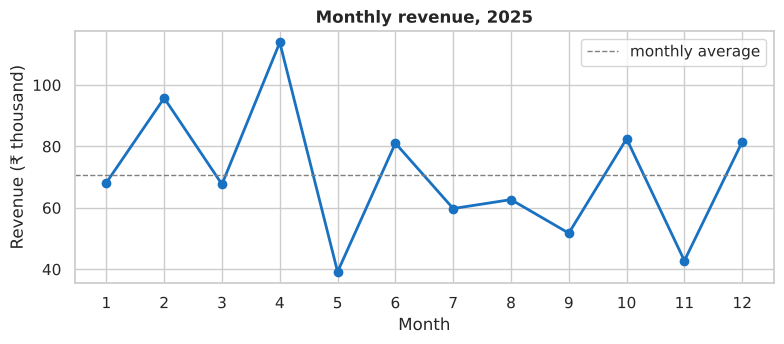

In [14]:
monthly = df.groupby("month")["revenue"].sum()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(monthly.index, monthly.values / 1000, marker="o", color="#1971C2", lw=2)
ax.axhline(monthly.mean() / 1000, ls="--", color="grey", lw=1, label="monthly average")
ax.set(title="Monthly revenue, 2025", xlabel="Month", ylabel="Revenue (₹ thousand)", xticks=range(1, 13)); ax.legend()
plt.tight_layout(); plt.show()

### 5.3 Histogram: distribution of order revenue

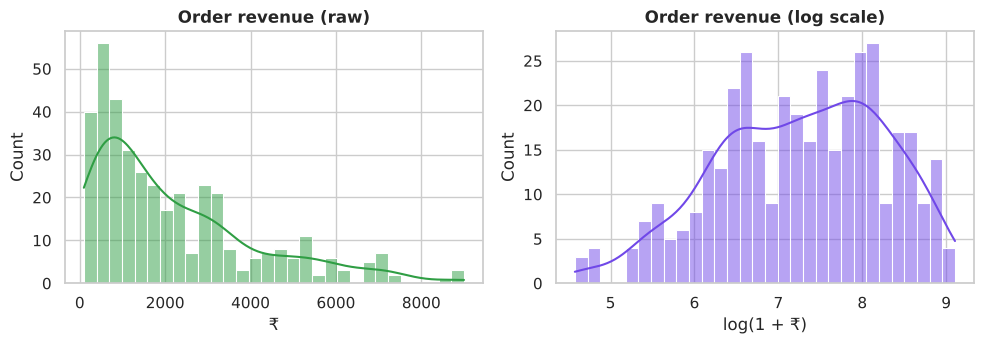

Skewness raw: 1.27 | log: -0.33


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sns.histplot(df["revenue"], bins=30, kde=True, color="#2F9E44", ax=axes[0]); axes[0].set(title="Order revenue (raw)", xlabel="₹")
sns.histplot(np.log1p(df["revenue"]), bins=30, kde=True, color="#7048E8", ax=axes[1]); axes[1].set(title="Order revenue (log scale)", xlabel="log(1 + ₹)")
plt.tight_layout(); plt.show()
print("Skewness raw:", round(df['revenue'].skew(), 2), "| log:", round(np.log1p(df['revenue']).skew(), 2))

### 5.4 Box plot: revenue by category and by customer segment

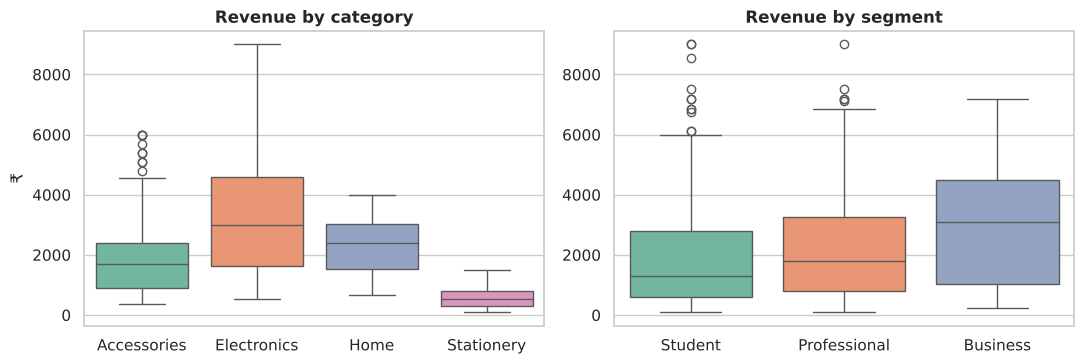

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x="category", y="revenue", hue="category", palette="Set2", legend=False, ax=axes[0]); axes[0].set(title="Revenue by category", xlabel="", ylabel="₹")
sns.boxplot(data=df, x="segment", y="revenue", hue="segment", palette="Set2", legend=False, ax=axes[1]); axes[1].set(title="Revenue by segment", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

### 5.5 Scatter plot: unit price vs revenue, coloured by quantity

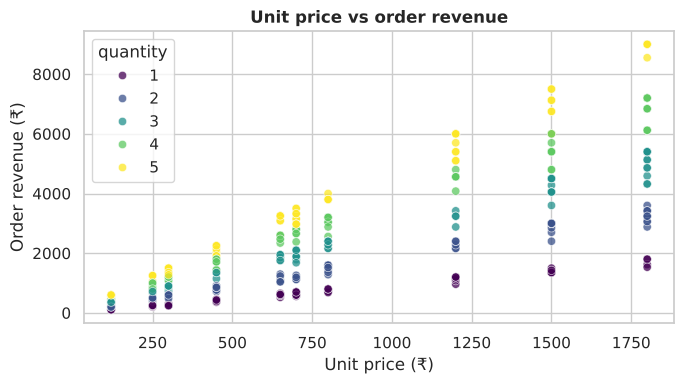

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sc = sns.scatterplot(data=df, x="unit_price", y="revenue", hue="quantity", palette="viridis", alpha=.75, ax=ax)
ax.set(title="Unit price vs order revenue", xlabel="Unit price (₹)", ylabel="Order revenue (₹)")
plt.tight_layout(); plt.show()

### 5.6 Heatmap, count plot and pair plot

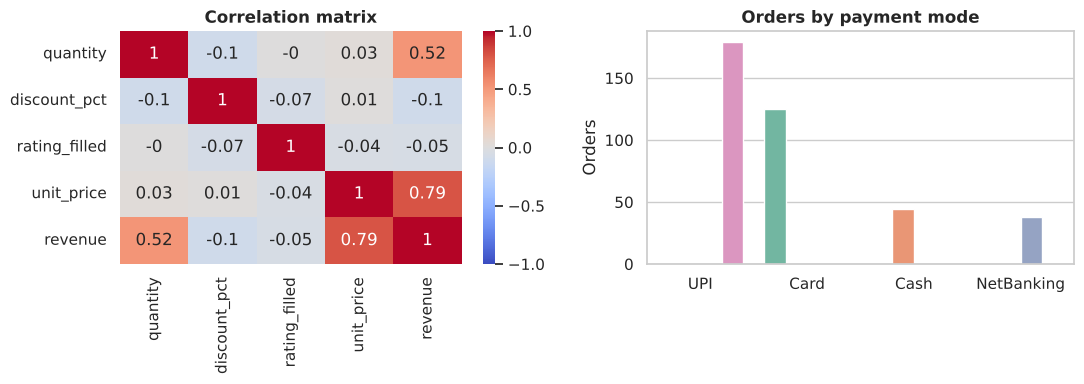

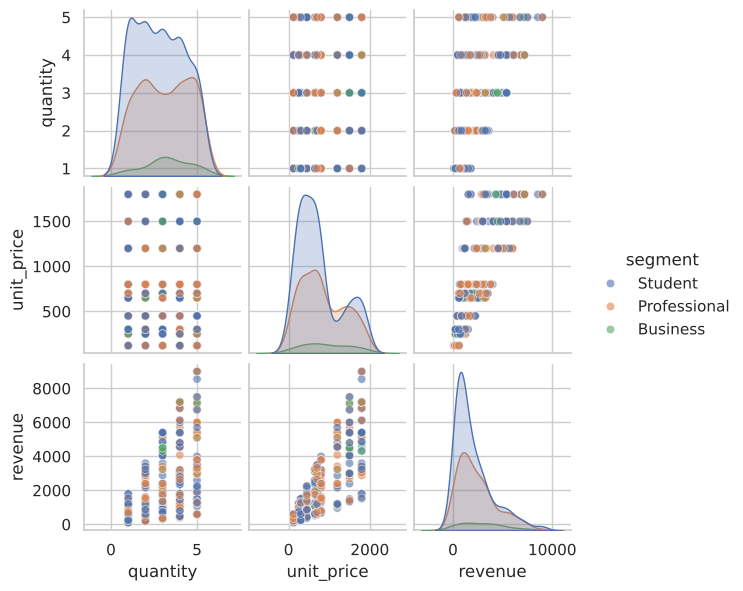

In [18]:
num = df[["quantity", "discount_pct", "rating_filled", "unit_price", "revenue"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(num.corr().round(2), annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Correlation matrix")
sns.countplot(data=df, x="payment_mode", hue="payment_mode", order=df["payment_mode"].value_counts().index, palette="Set2", legend=False, ax=axes[1])
axes[1].set(title="Orders by payment mode", xlabel="", ylabel="Orders")
plt.tight_layout(); plt.show()

sns.pairplot(df[["quantity", "unit_price", "revenue", "segment"]], hue="segment", height=2.0, plot_kws={"alpha": .6})
plt.show()

**Observations:** (1) Electronics generates about 63% of revenue and Stationery only about 8%. (2) Monthly revenue is volatile, from about ₹39k in May to about ₹114k in April, with no clear upward trend, so with one year of data I would not claim seasonality. (3) Order revenue is strongly right-skewed and looks much more bell-shaped on the log scale. (4) Box plots show Electronics has the highest median order value (₹3,000) and Stationery the lowest (₹540); by segment the Business median is highest (₹3,088) but there are few Business customers. (5) UPI is the most used payment mode (about 46% of orders).

## 6. Basic Data Analysis

### 6.1 Descriptive statistics

In [19]:
display(df[["quantity", "discount_pct", "rating_filled", "unit_price", "revenue"]].describe().round(2))
print("Mode of payment_mode:", df["payment_mode"].mode()[0])
print("Median vs mean revenue:", round(df['revenue'].median(), 1), "vs", round(df['revenue'].mean(), 1))
q1, q3 = df["revenue"].quantile([.25, .75]); iqr = q3 - q1
outl = df[df["revenue"] > q3 + 1.5 * iqr]
print(f"IQR outliers (revenue > {q3 + 1.5*iqr:,.0f}): {len(outl)} orders ({len(outl)/len(df):.1%})")

,quantity,discount_pct,rating_filled,unit_price,revenue
count,386.00,386.00,386.00,386.00,386.00
mean,2.95,6.54,3.81,787.75,2193.38
std,1.41,6.86,1.06,533.71,1935.86
min,1.00,0.00,1.00,120.00,96.00
25%,2.00,0.00,3.00,300.00,700.00
50%,3.00,5.00,4.00,700.00,1510.00
75%,4.00,10.00,5.00,1200.00,3134.38
max,5.00,20.00,5.00,1800.00,9000.00


Mode of payment_mode: UPI
Median vs mean revenue: 1510.0 vs 2193.4
IQR outliers (revenue > 6,786): 16 orders (4.1%)


### 6.2 Relationships and correlations

In [20]:
print(num.corr().round(3)["revenue"].sort_values(ascending=False))
print("\nDoes discount hurt revenue? mean revenue by discount level:")
print(df.groupby("discount_pct")["revenue"].agg(["count", "mean"]).round(0))
print("\nRating by category:"); print(df.groupby("category")["rating"].agg(["count", "mean"]).round(2))

revenue          1.000
unit_price       0.787
quantity         0.524
rating_filled   -0.048
discount_pct    -0.097
Name: revenue, dtype: float64

Does discount hurt revenue? mean revenue by discount level:
              count    mean
discount_pct               
0               156  2274.0
5                79  2454.0
10               68  2205.0
15               42  1863.0
20               41  1706.0

Rating by category:
             count  mean
category                
Accessories     69  3.49
Electronics    148  3.82
Home            41  4.05
Stationery     100  3.85


### 6.3 Patterns across groups

In [21]:
print("Revenue by region:"); print(df.groupby("region")["revenue"].agg(["sum", "mean"]).round(0).sort_values("sum", ascending=False))
print("\nRevenue share by segment:"); print((df.groupby("segment")["revenue"].sum() / df["revenue"].sum()).round(3))
print("\nTop 5 customers by revenue:"); print(df.groupby("customer_id")["revenue"].sum().nlargest(5).round(0))
print("\nBusiest weekday:"); print(df["order_date"].dt.day_name().value_counts().head(3))

Revenue by region:
             sum    mean
region                  
West    286478.0  2581.0
East    225619.0  2279.0
North   205832.0  2018.0
South   128714.0  1739.0

Revenue share by segment:
segment
Business        0.072
Professional    0.408
Student         0.520
Name: revenue, dtype: float64

Top 5 customers by revenue:
customer_id
C006    41862.0
C037    33900.0
C048    32065.0
C059    29418.0
C057    25755.0
Name: revenue, dtype: float64

Busiest weekday:
order_date
Friday      70
Saturday    59
Sunday      56
Name: count, dtype: int64


In [22]:
from scipy import stats
a = df.loc[df["segment"] == "Professional", "revenue"]; b = df.loc[df["segment"] == "Student", "revenue"]
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"Professional mean ₹{a.mean():,.0f} vs Student mean ₹{b.mean():,.0f} | Welch t = {t:.2f}, p = {p:.3f}")
print("Difference is", "statistically significant" if p < .05 else "NOT statistically significant", "at the 5% level")

Professional mean ₹2,401 vs Student mean ₹1,991 | Welch t = 1.99, p = 0.047
Difference is statistically significant at the 5% level


**Observations:** Revenue correlates most with unit price (r = 0.79) and quantity (r = 0.52), which is expected because revenue is calculated from them. Rating (r = -0.05) and discount (r = -0.10) have almost no linear relationship with revenue. Higher discount tiers show lower mean revenue (₹1,706 at 20% versus ₹2,274 at 0%), but this is only an association: the discount was not randomly assigned in this synthetic data. Students contribute 52% of revenue and Business customers 7%. Professionals spend slightly more per order than Students (Welch t-test p = 0.047), a borderline result that I would treat cautiously given the sample size and the many comparisons made.

## 7. Scikit-learn Check (environment test)

To confirm Scikit-learn works end-to-end, I train a small classifier on the built-in **Iris** dataset (real data, shipped with the library). This is a sanity check of the environment, not a modelling study.

Test accuracy: 0.921


Confusion matrix (rows = true class):
 [[12  0  0]
 [ 0 12  1]
 [ 0  2 11]]


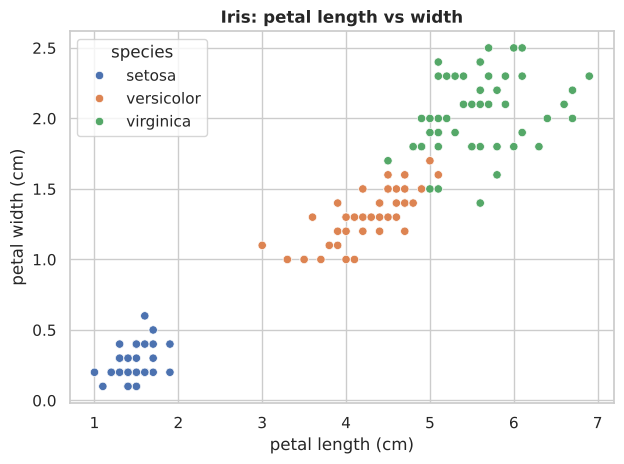

In [23]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)).fit(X_tr, y_tr)   # scaler fitted on train only
pred = model.predict(X_te)
print("Test accuracy:", round(accuracy_score(y_te, pred), 3))
print("Confusion matrix (rows = true class):\n", confusion_matrix(y_te, pred))
sns.scatterplot(data=X.assign(species=iris.target_names[y]), x="petal length (cm)", y="petal width (cm)", hue="species")
plt.title("Iris: petal length vs width"); plt.tight_layout(); plt.show()

## 8. Summary of Insights

**Key insights**
1. **Data quality:** about 7% of raw rows were unusable or duplicated; fixing types and labels was essential before any analysis.
2. **Revenue concentration:** Electronics earns about 63% of revenue; Stationery sells in volume but earns little.
3. **Distribution:** order values are right-skewed, so medians and log scales describe them better than means.
4. **Relationships:** price and quantity drive revenue; ratings and discounts show no meaningful linear link.
5. **Caution:** the data is synthetic, so these patterns illustrate technique rather than real business facts, and correlation is not causation.

**Skills demonstrated:** environment setup, Pandas/NumPy manipulation (select, filter, sort, merge, group, transform), systematic cleaning with validation, six chart types in Matplotlib/Seaborn, descriptive statistics and a hypothesis test, and a Scikit-learn pipeline check (Iris test accuracy 0.92).

### Reproducibility checklist
- Fixed random seed (`SEED = 42`) and library versions printed in Section 1
- Raw data never overwritten (`orders_raw.csv` kept; cleaning done on copies, output saved to `orders_clean.csv`)
- Cleaning decisions explained and validated with assertions
- Every chart titled, with labelled axes and units